## **FINAL PROJECT MODEL DEPLOYMENT**

**Name : Stevanus Gerald Marconus**  
**NIM : 2802392500**

**LAMPIRAN**  
Streamlit WEB -> https://2802392500sgm.streamlit.app/   
AWS Deploy -> http://13.222.180.158:8501/  
Link YT No 1 -> https://youtu.be/mPjmfmArPdc   
Link YT No 2 -> https://youtu.be/esRzVrUvkmg  
Link YT No 3 -> https://youtu.be/8iP63TzDi2w  

In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

**LOAD DATASET**

In [141]:
data = pd.read_csv('data_C.csv')
data

,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0,0x20419,CUS_0x36e1,August,Gellero,35,132-77-4921,Journalist,20364.57,1626.047500,...,Standard,2500.04,27.576478,9 Years and 8 Months,Yes,26.168109,92.51897591535379,High_spent_Small_value_payments,303.917665,Standard
1,1,0x4579,CUS_0x2a61,August,NaN,46,753-68-0048,Teacher,9786.86,951.571667,...,Standard,2149.9,23.451285,NaN,Yes,11.564437,54.46174813453877,Low_spent_Medium_value_payments,309.130981,Poor
2,2,0x1b923,CUS_0x788b,June,Ben Klaymane,19,276-42-6585,_______,146880.84,12372.070000,...,Good,387.53,31.100297,24 Years and 3 Months,No,98.031931,478.3574716999517,High_spent_Small_value_payments,920.817597,Standard
3,3,0x8ac9,CUS_0x5534,April,Aubinr,39,246-34-3138,Developer,23200.82,NaN,...,Standard,987.07,26.786925,17 Years and 7 Months,Yes,0.000000,65.84983488267585,Low_spent_Large_value_payments,391.890332,Standard
4,4,0x24a41,CUS_0x104f,April,Markm,20,264-84-8069,Architect,11336.835,992.736250,...,Standard,177.98,24.001752,14 Years and 7 Months,Yes,35.562731,NaN,Low_spent_Small_value_payments,228.245999,Standard
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,24995,0xd98c,CUS_0xc045,July,Sarahd,20,281-30-1712,Media_Manager,30622.73,2366.384852,...,_,383.33,34.502605,NaN,No,225.844807,__10000__,Low_spent_Small_value_payments,151.188270,Good
24996,24996,0x6864,CUS_0x93a5,July,Patrick Temple-Westt,45,905-92-0207,Lawyer,16060.675,1422.375479,...,_,57.82,23.638128,17 Years and 11 Months,Yes,196.565077,173.00838188143973,Low_spent_Small_value_payments,239.779603,Standard
24997,24997,0x1f9e6,CUS_0x18ca,January,Seetharamank,4824,300-10-5653,Engineer,79716.94,6372.078333,...,Good,1248.42,28.066339,19 Years and 5 Months,No,57.207322,107.61437209144957,High_spent_Large_value_payments,712.386140,Standard
24998,24998,0x878f,CUS_0x376e,June,Palmerz,47,084-31-1205,Mechanic,104255.67,8571.972500,...,Standard,992.62,42.756139,15 Years and 8 Months,No,133.991067,104.33015290773486,High_spent_Large_value_payments,858.876030,Standard


In [142]:
data.head(7)

,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0,0x20419,CUS_0x36e1,August,Gellero,35,132-77-4921,Journalist,20364.57,1626.047500,...,Standard,2500.04,27.576478,9 Years and 8 Months,Yes,26.168109,92.51897591535379,High_spent_Small_value_payments,303.917665,Standard
1,1,0x4579,CUS_0x2a61,August,NaN,46,753-68-0048,Teacher,9786.86,951.571667,...,Standard,2149.9,23.451285,NaN,Yes,11.564437,54.46174813453877,Low_spent_Medium_value_payments,309.130981,Poor
2,2,0x1b923,CUS_0x788b,June,Ben Klaymane,19,276-42-6585,_______,146880.84,12372.070000,...,Good,387.53,31.100297,24 Years and 3 Months,No,98.031931,478.3574716999517,High_spent_Small_value_payments,920.817597,Standard
3,3,0x8ac9,CUS_0x5534,April,Aubinr,39,246-34-3138,Developer,23200.82,NaN,...,Standard,987.07,26.786925,17 Years and 7 Months,Yes,0.000000,65.84983488267585,Low_spent_Large_value_payments,391.890332,Standard
4,4,0x24a41,CUS_0x104f,April,Markm,20,264-84-8069,Architect,11336.835,992.736250,...,Standard,177.98,24.001752,14 Years and 7 Months,Yes,35.562731,NaN,Low_spent_Small_value_payments,228.245999,Standard
5,5,0x16099,CUS_0x6573,August,Jamesp,34,682-25-4861,Doctor,8922.155,957.512917,...,Bad,4648.32,39.490786,2 Years and 4 Months,Yes,48.539005,102.11048074801573,!@9#%8,235.101806,Good
6,6,0x23e35,CUS_0xb3c2,April,Shirbonv,35,#F%$D@*&8,Media_Manager,20487.905,NaN,...,Good,1464.77,35.068620,20 Years and 11 Months,No,34.535295,64.78254782421534,High_spent_Medium_value_payments,318.114699,Standard


In [143]:
data.tail(7)

,Unnamed: 0,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
24993,24993,0x1e9d8,CUS_0x950,July,Alistair Barrf,45,296-43-7203,Engineer,102261.27,NaN,...,Standard,1164.89,32.529580,20 Years and 9 Months,No,79.779796,222.14766191165515,High_spent_Large_value_payments,811.249792,Standard
24994,24994,0x21c66,CUS_0x3f71,January,Gopinathl,25,624-03-0844,Mechanic,58048.82,4780.401667,...,Good,1020.94,31.874174,25 Years and 8 Months,No,93.477804,220.2549492381474,Low_spent_Small_value_payments,454.307413,Good
24995,24995,0xd98c,CUS_0xc045,July,Sarahd,20,281-30-1712,Media_Manager,30622.73,2366.384852,...,_,383.33,34.502605,NaN,No,225.844807,__10000__,Low_spent_Small_value_payments,151.188270,Good
24996,24996,0x6864,CUS_0x93a5,July,Patrick Temple-Westt,45,905-92-0207,Lawyer,16060.675,1422.375479,...,_,57.82,23.638128,17 Years and 11 Months,Yes,196.565077,173.00838188143973,Low_spent_Small_value_payments,239.779603,Standard
24997,24997,0x1f9e6,CUS_0x18ca,January,Seetharamank,4824,300-10-5653,Engineer,79716.94,6372.078333,...,Good,1248.42,28.066339,19 Years and 5 Months,No,57.207322,107.61437209144957,High_spent_Large_value_payments,712.386140,Standard
24998,24998,0x878f,CUS_0x376e,June,Palmerz,47,084-31-1205,Mechanic,104255.67,8571.972500,...,Standard,992.62,42.756139,15 Years and 8 Months,No,133.991067,104.33015290773486,High_spent_Large_value_payments,858.876030,Standard
24999,24999,0x1fc32,CUS_0x867f,January,Clarken,27,834-62-2160,Musician,18525.13,NaN,...,_,1632.9,27.901867,10 Years and 5 Months,Yes,18.408032,NaN,Low_spent_Small_value_payments,211.403531,Standard


### **Exploratory Data Analysis**

**Data Overview**

In [144]:
# Check dataset dimensions
data.shape

(25000, 29)

In [145]:
# Check dataset columns
data.columns

Index(['Unnamed: 0', 'ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN',
       'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary',
       'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
       'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment',
       'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix',
       'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

In [146]:
#Check dataset information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                25000 non-null  int64  
 1   ID                        25000 non-null  object 
 2   Customer_ID               25000 non-null  object 
 3   Month                     25000 non-null  object 
 4   Name                      22570 non-null  object 
 5   Age                       25000 non-null  object 
 6   SSN                       25000 non-null  object 
 7   Occupation                25000 non-null  object 
 8   Annual_Income             25000 non-null  object 
 9   Monthly_Inhand_Salary     21164 non-null  float64
 10  Num_Bank_Accounts         25000 non-null  int64  
 11  Num_Credit_Card           25000 non-null  int64  
 12  Interest_Rate             25000 non-null  int64  
 13  Num_of_Loan               25000 non-null  object 
 14  Type_o

In [147]:
# Check for any missing values
data.isnull().sum()

Unnamed: 0                     0
ID                             0
Customer_ID                    0
Month                          0
Name                        2430
Age                            0
SSN                            0
Occupation                     0
Annual_Income                  0
Monthly_Inhand_Salary       3836
Num_Bank_Accounts              0
Num_Credit_Card                0
Interest_Rate                  0
Num_of_Loan                    0
Type_of_Loan                2852
Delay_from_due_date            0
Num_of_Delayed_Payment      1792
Changed_Credit_Limit           0
Num_Credit_Inquiries         472
Credit_Mix                     0
Outstanding_Debt               0
Credit_Utilization_Ratio       0
Credit_History_Age          2240
Payment_of_Min_Amount          0
Total_EMI_per_month            0
Amount_invested_monthly     1134
Payment_Behaviour              0
Monthly_Balance              301
Credit_Score                   0
dtype: int64

In [148]:
# Check for any duplicated data
print(f"Number of Duplicated data : {data.duplicated().sum()}")

Number of Duplicated data : 0


In [149]:
# Check for summary statistics
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,25000.0,12499.500000,7217.022701,0.000000,6249.750000,12499.500000,18749.250000,24999.000000
Monthly_Inhand_Salary,21164.0,4189.505970,3208.575501,303.645417,1611.188333,3071.424583,5941.093333,15204.633333
Num_Bank_Accounts,25000.0,18.075360,122.375374,-1.000000,3.000000,6.000000,7.000000,1789.000000
Num_Credit_Card,25000.0,22.238000,126.156225,0.000000,4.000000,5.000000,7.000000,1498.000000
Interest_Rate,25000.0,75.407480,478.786499,1.000000,8.000000,14.000000,20.000000,5797.000000
Delay_from_due_date,25000.0,20.988400,14.851345,-5.000000,10.000000,18.000000,28.000000,67.000000
Num_Credit_Inquiries,24528.0,28.449976,197.078633,0.000000,3.000000,6.000000,9.000000,2592.000000
Credit_Utilization_Ratio,25000.0,32.277257,5.126823,20.100770,28.043382,32.309314,36.488060,50.000000
Total_EMI_per_month,25000.0,1465.714590,8514.582351,0.000000,30.181528,68.248891,159.990097,82331.000000
Monthly_Balance,24699.0,403.454486,215.613056,0.088628,269.935928,335.519841,472.202042,1564.134826


In [150]:
# Check unique values for Month
data['Month'].unique()

array(['August', 'June', 'April', 'July', 'February', 'May', 'January',
       'March'], dtype=object)

In [151]:
data['Month'].value_counts()

Month
February    3203
March       3192
January     3146
June        3144
May         3115
August      3075
April       3068
July        3057
Name: count, dtype: int64

In [152]:
# Check unique values for Occupation
data['Occupation'].unique()

array(['Journalist', 'Teacher', '_______', 'Developer', 'Architect',
       'Doctor', 'Media_Manager', 'Accountant', 'Entrepreneur', 'Lawyer',
       'Writer', 'Engineer', 'Manager', 'Musician', 'Scientist',
       'Mechanic'], dtype=object)

In [153]:
data['Occupation'].value_counts()

Occupation
_______          1765
Lawyer           1642
Mechanic         1621
Teacher          1618
Developer        1580
Journalist       1568
Scientist        1558
Accountant       1553
Media_Manager    1552
Architect        1550
Engineer         1549
Entrepreneur     1511
Doctor           1504
Manager          1497
Musician         1491
Writer           1441
Name: count, dtype: int64

In [154]:
# Check uniue payment of min ammount
data['Payment_of_Min_Amount'].unique()

array(['Yes', 'No', 'NM'], dtype=object)

In [155]:
data['Payment_of_Min_Amount'].value_counts()

Payment_of_Min_Amount
Yes    13082
No      8971
NM      2947
Name: count, dtype: int64

In [156]:
# Check uniqe values for Payment_Behaviour
data['Payment_Behaviour'].unique()

array(['High_spent_Small_value_payments',
       'Low_spent_Medium_value_payments',
       'Low_spent_Large_value_payments', 'Low_spent_Small_value_payments',
       '!@9#%8', 'High_spent_Medium_value_payments',
       'High_spent_Large_value_payments'], dtype=object)

In [157]:
data['Payment_Behaviour'].value_counts()

Payment_Behaviour
Low_spent_Small_value_payments      6377
High_spent_Medium_value_payments    4401
Low_spent_Medium_value_payments     3475
High_spent_Large_value_payments     3370
High_spent_Small_value_payments     2781
Low_spent_Large_value_payments      2645
!@9#%8                              1951
Name: count, dtype: int64

In [158]:
# Check unique values for type of loan
data['Type_of_Loan'].unique()

array(['Personal Loan, Student Loan, and Mortgage Loan',
       'Personal Loan, and Student Loan', 'Auto Loan', ...,
       'Student Loan, Debt Consolidation Loan, Home Equity Loan, Home Equity Loan, Not Specified, Mortgage Loan, and Student Loan',
       'Auto Loan, Not Specified, Auto Loan, Not Specified, Payday Loan, and Student Loan',
       'Home Equity Loan, Not Specified, Home Equity Loan, Debt Consolidation Loan, Mortgage Loan, and Debt Consolidation Loan'],
      dtype=object)

In [159]:
data['Type_of_Loan'].value_counts()

Type_of_Loan
Not Specified                                                                                                                                             345
Debt Consolidation Loan                                                                                                                                   338
Student Loan                                                                                                                                              332
Mortgage Loan                                                                                                                                             327
Personal Loan                                                                                                                                             318
                                                                                                                                                         ... 
Auto Loan, Student Loan, Mortgage Loan,

In [160]:
# Check unique values for Credit History
data['Credit_History_Age'].unique()

array(['9 Years and 8 Months', nan, '24 Years and 3 Months',
       '17 Years and 7 Months', '14 Years and 7 Months',
       '2 Years and 4 Months', '20 Years and 11 Months',
       '23 Years and 5 Months', '28 Years and 2 Months',
       '22 Years and 4 Months', '15 Years and 10 Months',
       '18 Years and 9 Months', '26 Years and 6 Months',
       '30 Years and 0 Months', '16 Years and 9 Months',
       '6 Years and 4 Months', '32 Years and 1 Months',
       '17 Years and 10 Months', '4 Years and 1 Months',
       '22 Years and 6 Months', '10 Years and 11 Months',
       '12 Years and 9 Months', '16 Years and 1 Months',
       '16 Years and 7 Months', '19 Years and 7 Months',
       '19 Years and 8 Months', '21 Years and 0 Months',
       '5 Years and 10 Months', '24 Years and 2 Months',
       '32 Years and 7 Months', '28 Years and 0 Months',
       '29 Years and 9 Months', '33 Years and 4 Months',
       '18 Years and 8 Months', '15 Years and 9 Months',
       '16 Years and 10 Mo

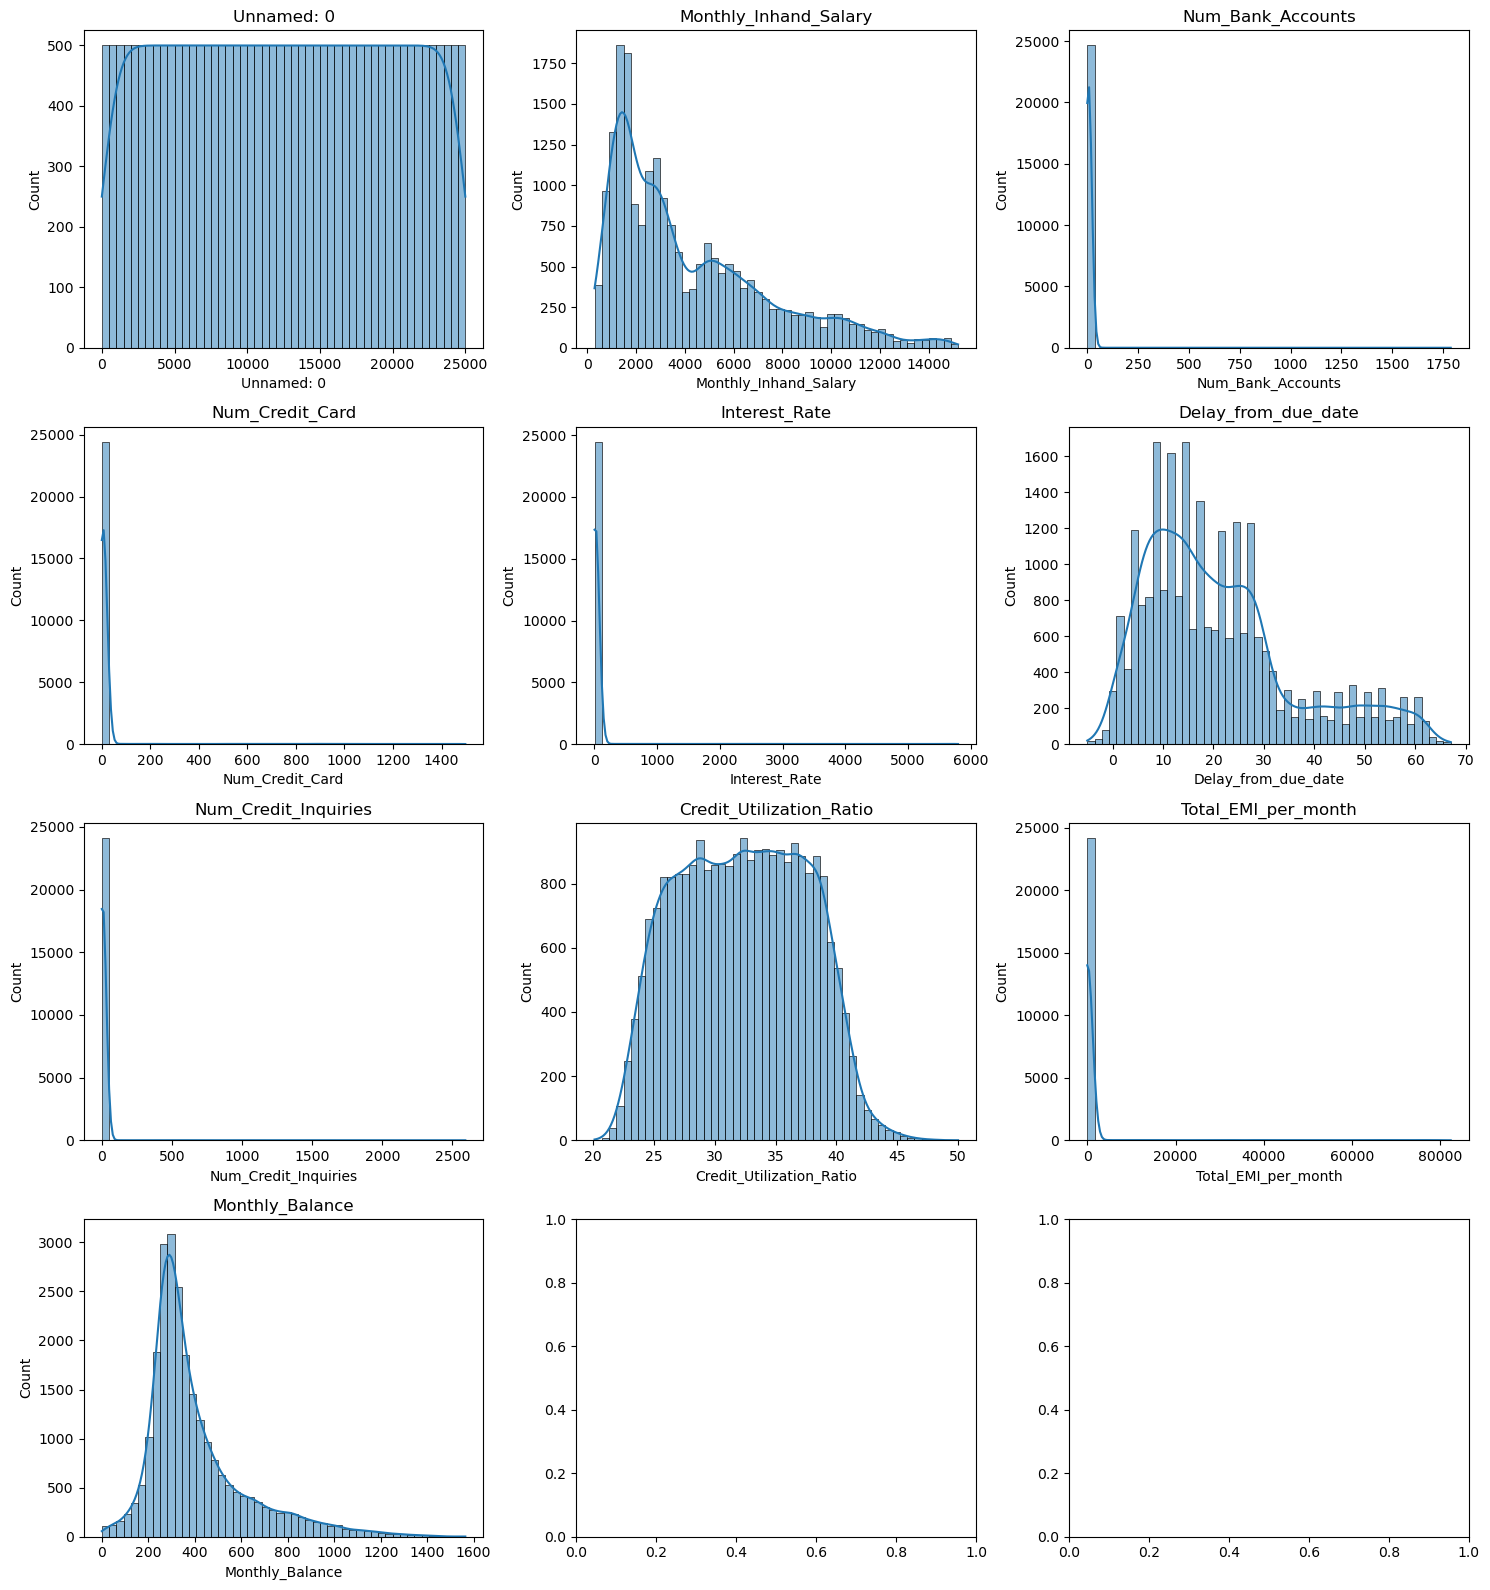

In [161]:
# Check the distribution 
num_cols = data.select_dtypes(include=['float64', 'int64']).columns
rows = (len(num_cols) + 2) // 3  
fig, axs = plt.subplots(rows, 3, figsize=(15, 4*rows))
axs = axs.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(data[col], bins=50, kde=True, ax=axs[i])
    axs[i].set_title(col)

plt.tight_layout()
plt.show()

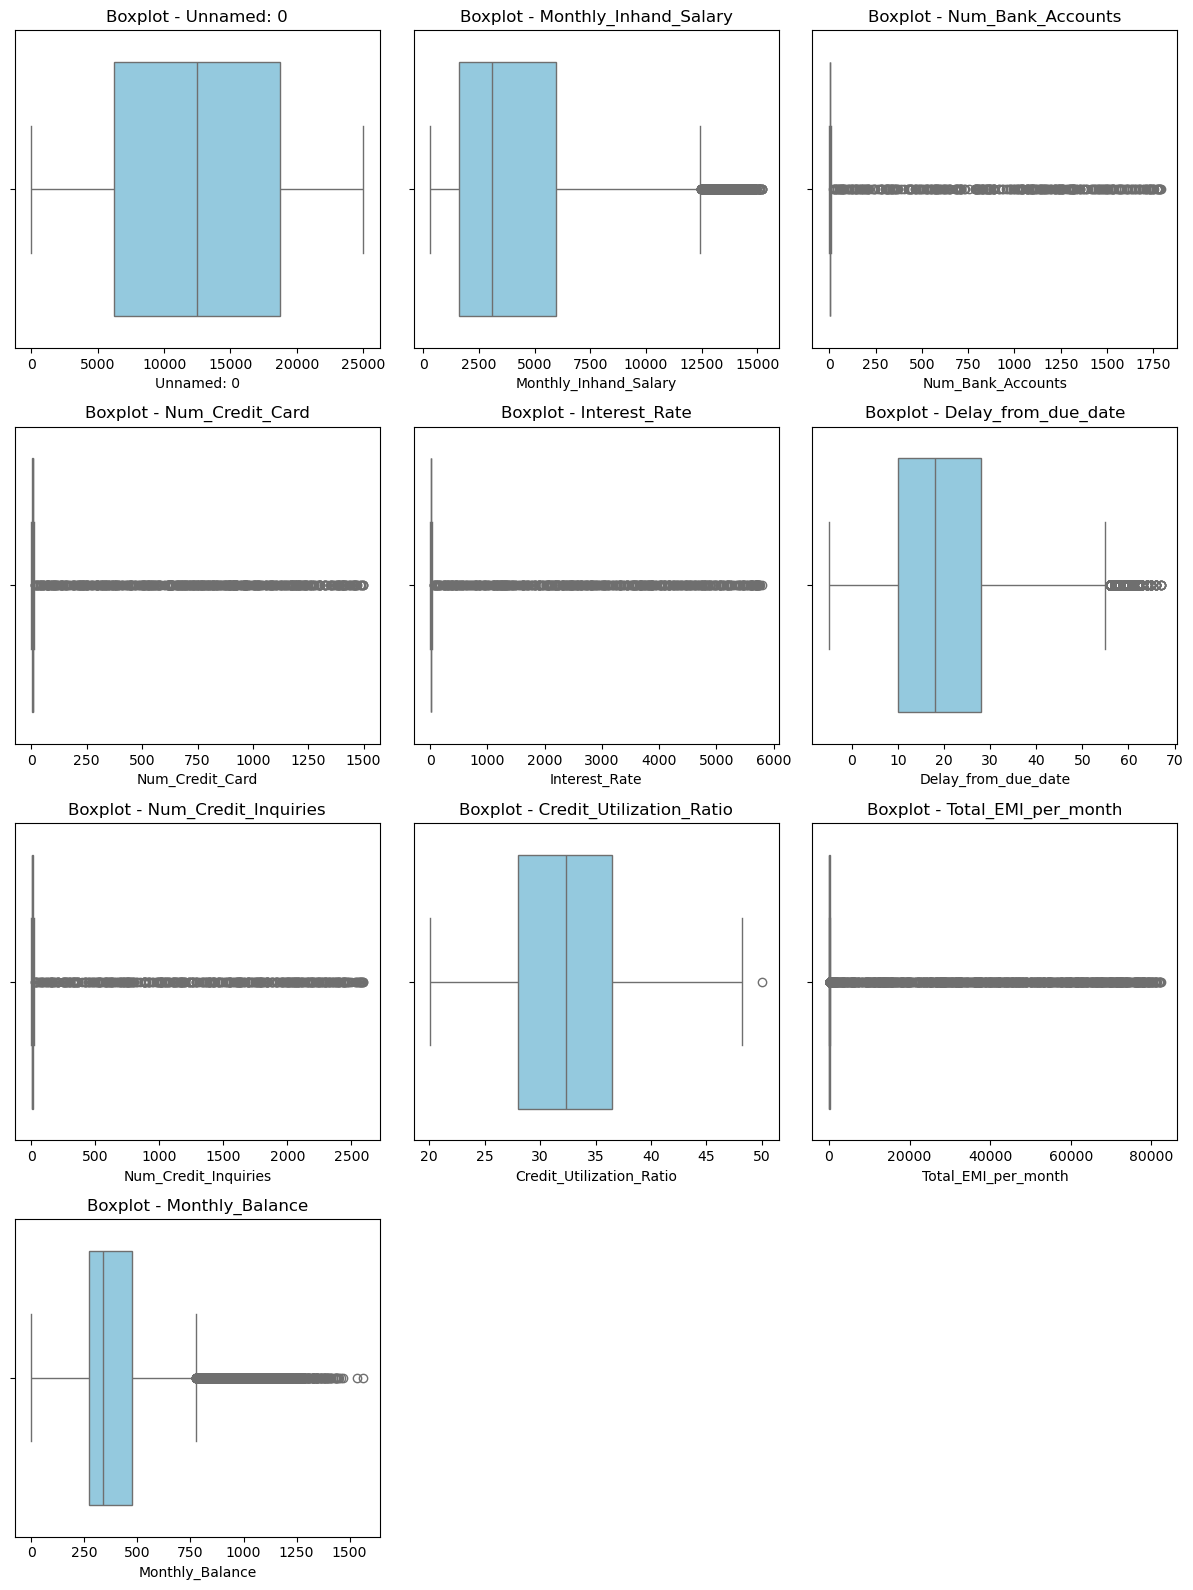

In [162]:
# Check for outliers in numerical columns with boxplot
n_cols = 3 
n_rows = (len(num_cols) + n_cols - 1) // n_cols 
plt.figure(figsize=(12, 4 * n_rows))
for i, col in enumerate(num_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(x=data[col], color='skyblue')
    plt.title(f'Boxplot - {col}')

plt.tight_layout()
plt.show()

In [163]:
# Check Target distribution for 'Credit_Score'
data['Credit_Score'].value_counts()

Credit_Score
Standard    13282
Poor         7268
Good         4450
Name: count, dtype: int64

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_14916\1174760581.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Credit_Score', data=data, palette='viridis')


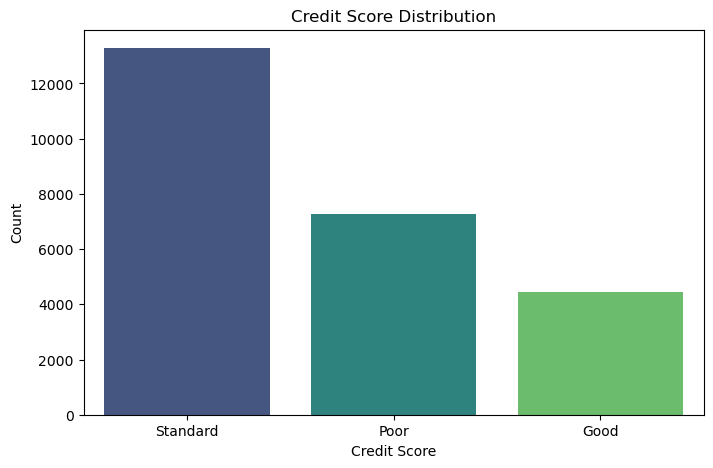

In [164]:
# Check target distribution plot for 'Credit_Score'
plt.figure(figsize=(8,5))
sns.countplot(x='Credit_Score', data=data, palette='viridis')
plt.title('Credit Score Distribution')
plt.xlabel('Credit Score')
plt.ylabel('Count')
plt.show()


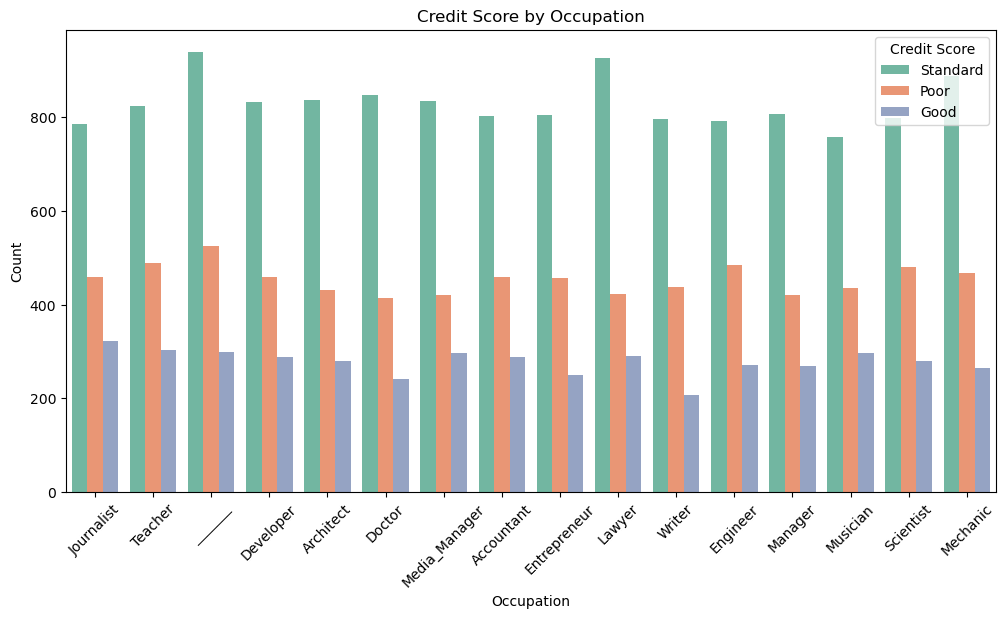

In [165]:
#Check taget vs Occupation
plt.figure(figsize=(12,6))
sns.countplot(x='Occupation', hue='Credit_Score', data=data, palette='Set2')
plt.title('Credit Score by Occupation')
plt.xlabel('Occupation')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Credit Score')
plt.show()

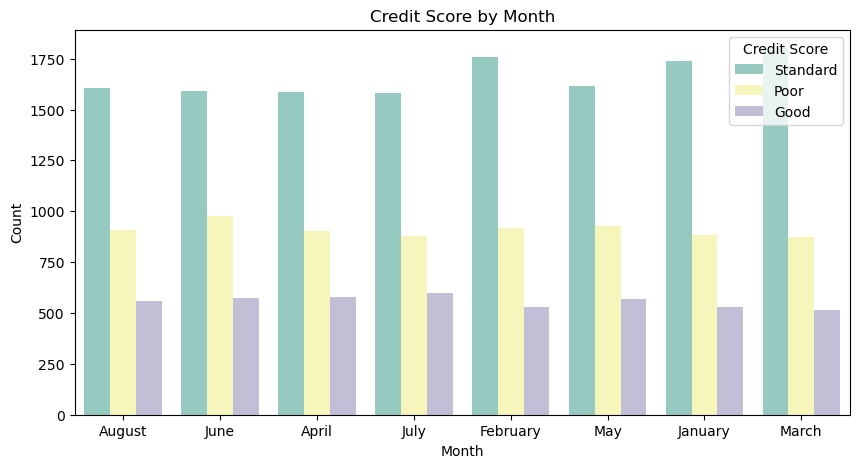

In [166]:
# Check target vs month
plt.figure(figsize=(10,5))
sns.countplot(x='Month', hue='Credit_Score', data=data, palette='Set3')
plt.title('Credit Score by Month')
plt.xlabel('Month')
plt.ylabel('Count')
plt.legend(title='Credit Score')
plt.show()

**Data Condition :**  
1. The dataset contain missing values. But since the number of missing values is not that big, we could do inputation.
2. There is no Duplicated data.
3. There are so many Features that have the wrong datatype such as 'age','Annual_Income', 'Monthly_Inhand_Salary','Outstanding_Debt', 'Total_EMI_per_month' 'Amount_invested_monthly', 'Changed_Credit_Limit', that should be a numerical not categorical datatype.
4. In some categorical columns, there is some abnormal values, so we have to convert it to 'unknown'.
5. There are some outliers in numerical features in the dataset.
6. Some Categorical must be Clean adn Encode, especially the Target Columns.  
7. There is some uninformative columns like ID, ect.
8. Based on the last figure, we can conclude that different occupation didn't affect to the Target result.  
9. The target variable shows a slight imbalance between classes, which should be considered during modeling.

**TIDY UP DATA**

**SPLIT THE DATASET**

In [167]:
# drop unnecessary columns
data_clean = data.drop(columns=['Unnamed: 0','ID','Customer_ID','SSN','Name','Month','Type_of_Loan','Credit_History_Age'])

In [168]:
# Set input and output features
input = data_clean.drop(['Credit_Score'],axis = 1)
output =  data_clean['Credit_Score']

In [169]:
# Split the dataset into training, validation, and testing sets (80% train, 10% val, 10% test)
x_train, x_test, y_train, y_test = train_test_split(input, output, test_size = 0.2, random_state = 42,stratify=output)

In [170]:
print('jumlah data train: ',x_train.shape)
print('jumlah data test: ',x_test.shape)

jumlah data train:  (20000, 20)
jumlah data test:  (5000, 20)


In [171]:
# Typecast Age & Num_of_loan to numeric
x_train['Age'] = pd.to_numeric(x_train['Age'], errors='coerce')
x_test['Age']  = pd.to_numeric(x_test['Age'], errors='coerce')

x_train['Num_of_Loan'] = pd.to_numeric(x_train['Num_of_Loan'], errors='coerce')
x_test['Num_of_Loan']  = pd.to_numeric(x_test['Num_of_Loan'], errors='coerce')

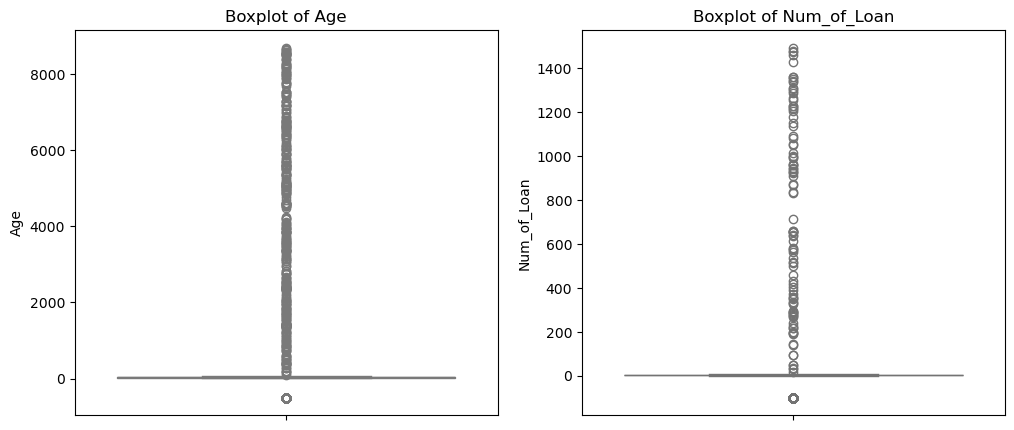

In [172]:
# Box plot to check outliers in Age and Num_of_Loan
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=x_train['Age'], color='lightblue')
plt.title('Boxplot of Age')
plt.subplot(1, 2, 2)
sns.boxplot(y=x_train['Num_of_Loan'], color='lightgreen')
plt.title('Boxplot of Num_of_Loan')
plt.show()

In [173]:
x_train.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,19022.0,106.838923,666.782711,-500.000000,24.000000,33.000000,42.000000,8697.000000
Monthly_Inhand_Salary,16931.0,4187.204633,3219.762622,303.645417,1609.976250,3059.204167,5922.029167,15204.633333
Num_Bank_Accounts,20000.0,18.532950,125.125850,-1.000000,3.000000,6.000000,7.000000,1789.000000
Num_Credit_Card,20000.0,22.056800,126.274009,0.000000,4.000000,5.000000,7.000000,1498.000000
Interest_Rate,20000.0,73.732750,470.262903,1.000000,8.000000,14.000000,20.000000,5797.000000
Num_of_Loan,19041.0,3.069849,63.854203,-100.000000,1.000000,3.000000,5.000000,1495.000000
Delay_from_due_date,20000.0,21.009900,14.773534,-5.000000,10.000000,18.000000,28.000000,67.000000
Num_Credit_Inquiries,19622.0,28.898481,200.401638,0.000000,3.000000,6.000000,9.000000,2592.000000
Credit_Utilization_Ratio,20000.0,32.292129,5.147605,20.100770,28.043651,32.309314,36.520487,50.000000
Total_EMI_per_month,20000.0,1455.954180,8464.795217,0.000000,29.957461,68.086281,158.618357,82178.000000


In [174]:
# Handle abnormal values in 'Age' 
x_train.loc[(x_train['Age'] < 18) | (x_train['Age'] > 100), 'Age'] = np.nan
x_test.loc[(x_test['Age'] < 18) | (x_test['Age'] > 100), 'Age'] = np.nan


In [175]:
# Clean numeric columns with string values
def clean_numeric(x):
    if isinstance(x, str):
        x = x.replace('_','').replace(',','')
        try:
            return float(x)
        except:
            return np.nan
    return x

num_str_cols = [
    'Annual_Income',
    'Monthly_Inhand_Salary',
    'Outstanding_Debt',
    'Total_EMI_per_month',
    'Amount_invested_monthly',
    'Changed_Credit_Limit'
]

for col in num_str_cols:
    x_train[col] = x_train[col].apply(clean_numeric)
    x_test[col]  = x_test[col].apply(clean_numeric)

In [176]:
# Handle outliers and negative values in specific columns
col_handle = ['Interest_Rate', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Num_of_Loan', 'Num_Credit_Inquiries', 'Delay_from_due_date']
for col in col_handle:
    x_train.loc[x_train[col] < 0, col] = 0
    x_test.loc[x_test[col] < 0, col] = 0
    upper = x_train[col].quantile(0.99)
    x_train.loc[x_train[col] > upper, col] = upper
    x_test.loc[x_test[col] > upper, col] = upper

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_14916\1972845112.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2804.129999999979' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  x_train.loc[x_train[col] > upper, col] = upper
C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_14916\1972845112.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2804.129999999979' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  x_test.loc[x_test[col] > upper, col] = upper
C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_14916\1972845112.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '589.0599999999904' has dtype incompatible with int64, please explicitly cast to a compati

In [177]:
# Handle Invalid Occupation entries in 'Occupation' column
x_train['Occupation'] = x_train['Occupation'].replace('_______', 'Unknown')
x_test['Occupation'] = x_test['Occupation'].replace('_______', 'Unknown')

In [178]:
# Handle payment behaviour column with invalid entries
x_train['Payment_Behaviour'] = x_train['Payment_Behaviour'].replace('!@9#%8', 'Unknown')
x_test['Payment_Behaviour'] = x_test['Payment_Behaviour'].replace('!@9#%8', 'Unknown')

In [179]:
# Define categorical and numerical columns
cat_cols = x_train.select_dtypes(include='object').columns
num_cols = x_train.select_dtypes(exclude='object').columns


In [180]:
# Handle missing values with imputation in categorial columns
for col in cat_cols:
    mode = x_train[col].mode()[0]
    x_train[col] = x_train[col].fillna(mode)
    x_test[col]  = x_test[col].fillna(mode)

In [181]:
# Handle missing values with median in numerical columns
for col in num_cols:
    median = x_train[col].median()
    x_train[col] = x_train[col].fillna(median)
    x_test[col]  = x_test[col].fillna(median)

# I Choose to use imputation rather than deleting rows with missing values to preserve data integrity and avoid losing potentially valuable information.
# I choose median for numerical columns to mitigate the impact of outliers, since the distribution of numerical data can be skewed by extreme values.

In [182]:
# Final check for missing values
x_train.isnull().sum()

Age                         0
Occupation                  0
Annual_Income               0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Payment_Behaviour           0
Monthly_Balance             0
dtype: int64

In [183]:
# Check SUmmary statistics after cleaning
x_train.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,20000.0,34.294850,9.353111e+00,18.000000,27.000000,34.000000,41.000000,9.500000e+01
Annual_Income,20000.0,157585.437701,1.324314e+06,7005.930000,19167.220000,37024.700000,72389.880000,2.416001e+07
Monthly_Inhand_Salary,20000.0,4014.112961,2.990199e+03,303.645417,1770.946667,3059.204167,5343.115000,1.520463e+04
Num_Bank_Accounts,20000.0,12.473750,6.221442e+01,0.000000,3.000000,6.000000,7.000000,5.890600e+02
Num_Credit_Card,20000.0,18.880600,9.720672e+01,0.000000,4.000000,5.000000,7.000000,8.260100e+02
Interest_Rate,20000.0,58.441050,3.263432e+02,1.000000,8.000000,14.000000,20.000000,2.804130e+03
Num_of_Loan,20000.0,3.394550,2.456335e+00,0.000000,2.000000,3.000000,5.000000,9.000000e+00
Delay_from_due_date,20000.0,21.006800,1.471783e+01,0.000000,10.000000,18.000000,28.000000,6.100000e+01
Changed_Credit_Limit,20000.0,10.355130,6.732332e+00,-6.480000,5.400000,9.410000,14.680000,3.491000e+01
Num_Credit_Inquiries,20000.0,21.303976,1.277893e+02,0.000000,3.000000,6.000000,9.000000,1.166160e+03


In [184]:
# Check Data train info after cleaning
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 667 to 14973
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       20000 non-null  float64
 1   Occupation                20000 non-null  object 
 2   Annual_Income             20000 non-null  float64
 3   Monthly_Inhand_Salary     20000 non-null  float64
 4   Num_Bank_Accounts         20000 non-null  float64
 5   Num_Credit_Card           20000 non-null  float64
 6   Interest_Rate             20000 non-null  float64
 7   Num_of_Loan               20000 non-null  float64
 8   Delay_from_due_date       20000 non-null  int64  
 9   Num_of_Delayed_Payment    20000 non-null  object 
 10  Changed_Credit_Limit      20000 non-null  float64
 11  Num_Credit_Inquiries      20000 non-null  float64
 12  Credit_Mix                20000 non-null  object 
 13  Outstanding_Debt          20000 non-null  float64
 14  Credit_Ut

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_14916\2958015238.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_to_target.drop('Target_Num').values, y=corr_to_target.drop('Target_Num').index, palette='RdYlGn')


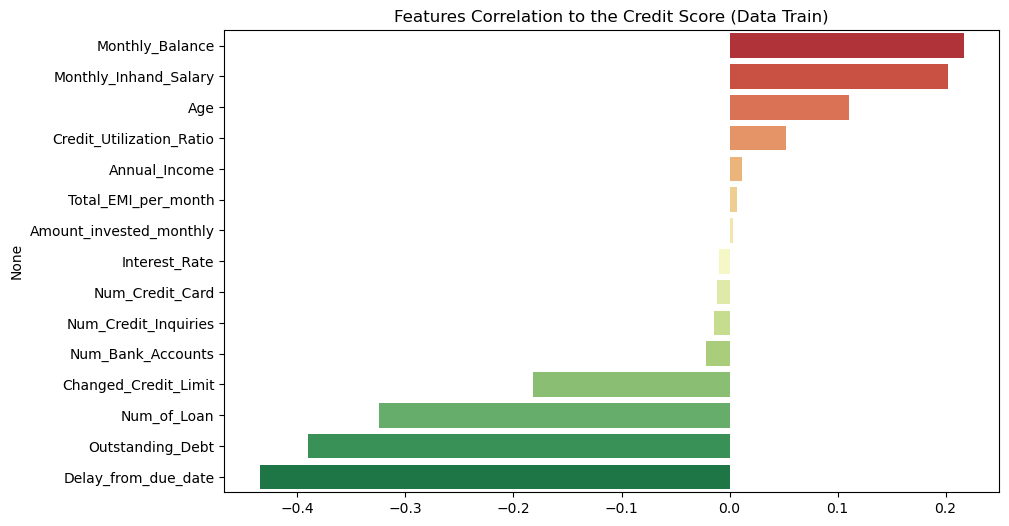

Correlation Score Fitur vs Target:
Monthly_Balance             0.217004
Monthly_Inhand_Salary       0.202366
Age                         0.110735
Credit_Utilization_Ratio    0.051832
Annual_Income               0.011733
Total_EMI_per_month         0.007031
Amount_invested_monthly     0.003049
Interest_Rate              -0.009758
Num_Credit_Card            -0.011890
Num_Credit_Inquiries       -0.014251
Num_Bank_Accounts          -0.021804
Changed_Credit_Limit       -0.181494
Num_of_Loan                -0.323986
Outstanding_Debt           -0.389815
Delay_from_due_date        -0.435000
Name: Target_Num, dtype: float64


In [185]:
# Check Correlation to target variable
temp_train = x_train.copy()
target_map = {'Poor': 0, 'Standard': 1, 'Good': 2}
temp_train['Target_Num'] = y_train.map(target_map)


corr_to_target = temp_train.select_dtypes(include=[np.number]).corr()['Target_Num'].sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=corr_to_target.drop('Target_Num').values, y=corr_to_target.drop('Target_Num').index, palette='RdYlGn')
plt.title("Features Correlation to the Credit Score (Data Train)")
plt.show()
print("Correlation Score Fitur vs Target:")
print(corr_to_target.drop('Target_Num'))

### **DATA PREPROCESSING**

In [186]:
# Define categorical and numerical columns
cat_cols = x_train.select_dtypes(include='object').columns
num_cols = x_train.select_dtypes(exclude='object').columns

In [187]:
# scale numerical features
scaler = RobustScaler()
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols]  = scaler.transform(x_test[num_cols])

In [188]:
ohe = OneHotEncoder(handle_unknown='ignore',sparse_output=False)

x_train_cat = ohe.fit_transform(x_train[cat_cols])
x_test_cat  = ohe.transform(x_test[cat_cols])

ohe_cols = ohe.get_feature_names_out(cat_cols)

In [189]:
x_train_final = pd.concat([
    pd.DataFrame(x_train_cat, columns=ohe_cols, index=x_train.index),
    x_train[num_cols]
], axis=1)

x_test_final = pd.concat([
    pd.DataFrame(x_test_cat, columns=ohe_cols, index=x_test.index),
    x_test[num_cols]
], axis=1)

In [190]:
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)
y_test_enc = label_encoder.transform(y_test)

In [191]:
# SMOTE the imbalanced data
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train_final, y_train_enc)

In [192]:
x_train_smote

,Occupation_Accountant,Occupation_Architect,Occupation_Developer,Occupation_Doctor,Occupation_Engineer,Occupation_Entrepreneur,Occupation_Journalist,Occupation_Lawyer,Occupation_Manager,Occupation_Mechanic,...,Interest_Rate,Num_of_Loan,Delay_from_due_date,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
0,0.000000,0.000000,0.0,0.000000,0.0,1.0,0.0,0.000000,0.000000,0.0,...,-0.416667,0.000000,-0.333333,0.087284,-0.666667,0.004724,-0.710342,2.138203,3.163393,1.489332
1,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,...,-0.250000,0.333333,-0.055556,0.056034,0.000000,-0.660401,-0.918159,0.145620,-0.442035,0.101451
2,0.000000,0.000000,0.0,0.000000,0.0,0.0,1.0,0.000000,0.000000,0.0,...,0.250000,0.333333,0.000000,0.923491,0.166667,0.530580,0.708007,0.323595,55.304806,-0.416615
3,0.000000,0.000000,0.0,0.000000,0.0,0.0,1.0,0.000000,0.000000,0.0,...,-0.166667,-0.333333,-0.277778,-0.240302,-0.666667,0.087024,0.696235,0.785353,4.091266,-0.504084
4,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,1.0,...,-0.166667,0.000000,-0.166667,-0.709052,-1.000000,-0.746844,1.344048,2.092084,2.217992,2.466726
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31873,0.000000,0.000000,0.0,0.506351,0.0,0.0,0.0,0.000000,0.493649,0.0,...,1.041137,1.831216,1.673017,0.561723,0.997883,2.554703,-0.088445,-0.026134,-0.475136,-0.398456
31874,0.028484,0.971516,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,...,1.497626,0.638183,0.436532,0.757878,0.023736,1.094249,-0.360671,0.024041,-0.324145,-0.187559
31875,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.723761,0.000000,0.0,...,1.019801,0.517493,0.760892,0.098879,0.350826,0.966063,-0.114292,-0.255410,0.005410,-0.483589
31876,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,...,153.149914,1.056521,1.172825,-0.530373,0.528261,0.560844,-1.032603,-0.176100,-0.310464,-0.419026


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_14916\1246419270.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Credit_Score', data=data_smote, palette='viridis')


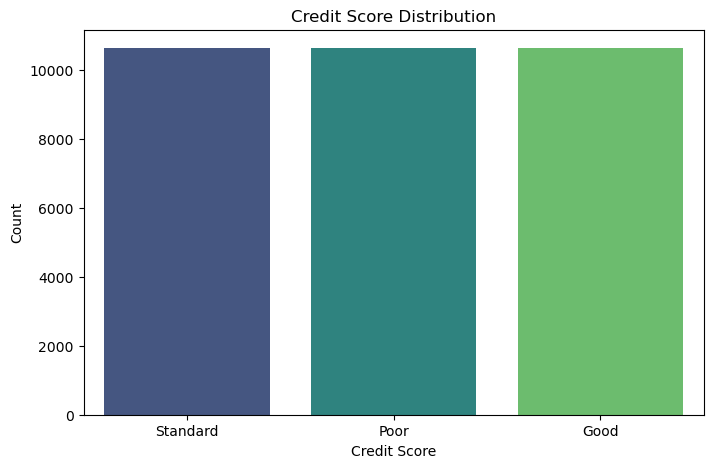

In [193]:
# Check target distribution plot for 'Credit_Score' after SMOTE
data_smote = pd.DataFrame({'Credit_Score':label_encoder.inverse_transform(y_train_smote)})
plt.figure(figsize=(8,5))
sns.countplot(x='Credit_Score', data=data_smote, palette='viridis')
plt.title('Credit Score Distribution')
plt.xlabel('Credit Score')
plt.ylabel('Count')
plt.show()


### **MODELING**

#### **Create Object Oriented Program Model**

In [194]:
from abc import ABC, abstractmethod

In [195]:
class BaseModel(ABC):
    def __init__(self, name):
        self.name           = name
        self.model_         = None   
        self.metrics_       = {}    
        self.y_pred_        = None   

    @abstractmethod
    def train(self, X_train, y_train):
        pass

    @abstractmethod
    def test(self, X_test, y_test):
        pass

    def _compute_metrics(self, y_test, y_pred):
        self.y_pred_  = y_pred
        self.y_test_  = y_test
        self.metrics_ = {
            'accuracy' : accuracy_score(self.y_test_, self.y_pred_),
            'precision': precision_score(self.y_test_, self.y_pred_, average='weighted', zero_division=0),
            'recall'   : recall_score(self.y_test_, self.y_pred_, average='weighted', zero_division=0),
            'f1'       : f1_score(self.y_test_, self.y_pred_, average='weighted', zero_division=0),
        }
        return self.metrics_

    def report(self):
        print(classification_report(
            self.y_test_,
            self.y_pred_,
        ))

#### **Create Model 1**

In [196]:
class RandomForestModel1(BaseModel):
    def __init__(self, name, param_grid=None, cv=3):
        super().__init__(name)  
        self.param_grid   = param_grid or {
            'n_estimators'     : [100, 200, 300],
            'max_depth'        : [10, 20, None],
            'min_samples_split': [2, 5, 10]
        }
        self.cv           = cv
        self.best_params_ = None

    def train(self, X_train, y_train):
        rf   = RandomForestClassifier(random_state=42)
        grid = GridSearchCV(
            rf, self.param_grid,
            cv=self.cv, scoring='f1_weighted',
            n_jobs=-1, verbose=0
        )
        grid.fit(X_train, y_train)
        self.model_       = grid.best_estimator_
        self.best_params_ = grid.best_params_
        return self

    def test(self, X_test, y_test):
        y_pred = self.model_.predict(X_test)
        self._compute_metrics(y_test, y_pred)  
        return self
    
    

#### **Create Model 2**

In [197]:
class XGBoostModel2(BaseModel):
    def __init__(self, name, param_grid=None, cv=3):
        super().__init__(name)  
        self.param_grid   = param_grid or {
            'n_estimators' : [100, 200],
            'max_depth'    : [3, 6, 9],
            'learning_rate': [0.05, 0.1]
        }
        self.cv           = cv
        self.best_params_ = None

    def train(self, X_train, y_train):
        xgb  = XGBClassifier(
            objective='multi:softmax',
            eval_metric='mlogloss',
            random_state=42,
            verbosity=0
        )
        grid = GridSearchCV(
            xgb, self.param_grid,
            cv=self.cv, scoring='f1_weighted',
            n_jobs=-1, verbose=0
        )
        grid.fit(X_train, y_train)
        self.model_       = grid.best_estimator_
        self.best_params_ = grid.best_params_
        return self

    def test(self, X_test, y_test):
        y_pred = self.model_.predict(X_test)
        self._compute_metrics(y_test, y_pred)  
        return self


#### **Create Model 3**

In [198]:
class LightGBMModel3(BaseModel):
    def __init__(self, name, param_grid=None, cv=3):
        super().__init__(name)
        self.param_grid = param_grid or {
            'n_estimators' : [200, 300],
            'max_depth'    : [6, 8],
            'learning_rate': [0.05, 0.1],
            'num_leaves'   : [31, 63]
        }
        self.cv           = cv
        self.best_params_ = None

    def train(self, X_train, y_train):
        lgbm = LGBMClassifier(
            objective='multiclass',
            random_state=42,
            verbose=-1
        )
        grid = GridSearchCV(
            lgbm, self.param_grid,
            cv=self.cv, scoring='f1_weighted',
            n_jobs=-1, verbose=0
        )
        grid.fit(X_train, y_train)
        self.model_       = grid.best_estimator_
        self.best_params_ = grid.best_params_
        return self

    def test(self, X_test, y_test):
        y_pred = self.model_.predict(X_test)
        self._compute_metrics(y_test, y_pred)
        return self

### **TRAINING**

#### **Model1**

**Train with non SMOTE**

In [199]:
model1 = RandomForestModel1('Random Forest')

model1.train(x_train_final, y_train_enc)

In [200]:
model1.test(x_test_final, y_test_enc)
model1.metrics_
model1.report()

              precision    recall  f1-score   support

           0       0.62      0.69      0.65       890
           1       0.73      0.70      0.71      1454
           2       0.76      0.75      0.76      2656

    accuracy                           0.73      5000
   macro avg       0.70      0.71      0.71      5000
weighted avg       0.73      0.73      0.73      5000



In [201]:
model1.metrics_

{'accuracy': 0.7254,
 'precision': 0.7275519203392325,
 'recall': 0.7254,
 'f1': 0.7260833521310334}

**Train with SMOTE DATA**

In [202]:
model1_S = RandomForestModel1('Random Forest Smote')

model1_S.train(x_train_smote, y_train_smote)

In [203]:
model1_S.test(x_test_final, y_test_enc)
model1_S.metrics_

{'accuracy': 0.7218,
 'precision': 0.740159563598167,
 'recall': 0.7218,
 'f1': 0.7244416842396376}

In [204]:
model1_S.best_params_

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}

In [205]:
model1_S.report()

              precision    recall  f1-score   support

           0       0.58      0.79      0.67       890
           1       0.70      0.75      0.73      1454
           2       0.82      0.68      0.74      2656

    accuracy                           0.72      5000
   macro avg       0.70      0.74      0.71      5000
weighted avg       0.74      0.72      0.72      5000



#### **Model 2**

**Train with non SMOTE**

In [206]:
model2 = XGBoostModel2('XGBoost')
model2.train(x_train_final, y_train_enc)

In [207]:
model2.test(x_test_final, y_test_enc)
model2.metrics_

{'accuracy': 0.7234,
 'precision': 0.7237771013437989,
 'recall': 0.7234,
 'f1': 0.723412116687868}

In [208]:
model2.report()

              precision    recall  f1-score   support

           0       0.63      0.64      0.64       890
           1       0.74      0.70      0.72      1454
           2       0.75      0.76      0.76      2656

    accuracy                           0.72      5000
   macro avg       0.70      0.70      0.70      5000
weighted avg       0.72      0.72      0.72      5000



**Train with SMOTE Data**

In [209]:
model2_S = XGBoostModel2('XGBoost Smote')
model2_S.train(x_train_smote, y_train_smote)

In [210]:
model2_S.test(x_test_final, y_test_enc)
model2_S.metrics_


{'accuracy': 0.7138,
 'precision': 0.7281855064204779,
 'recall': 0.7138,
 'f1': 0.716405272797378}

In [211]:
model2_S.report()

              precision    recall  f1-score   support

           0       0.57      0.77      0.66       890
           1       0.70      0.73      0.71      1454
           2       0.80      0.69      0.74      2656

    accuracy                           0.71      5000
   macro avg       0.69      0.73      0.70      5000
weighted avg       0.73      0.71      0.72      5000



#### **Model 3**

**Training with NON SMOTE**

In [212]:
model3 = LightGBMModel3('LightGBM')
model3.train(x_train_final, y_train_enc)

In [213]:
model3.test(x_test_final, y_test_enc)
model3.metrics_

{'accuracy': 0.7192,
 'precision': 0.720091889055731,
 'recall': 0.7192,
 'f1': 0.7195152307759223}

In [214]:
model3.report()

              precision    recall  f1-score   support

           0       0.61      0.64      0.62       890
           1       0.73      0.70      0.71      1454
           2       0.75      0.76      0.75      2656

    accuracy                           0.72      5000
   macro avg       0.70      0.70      0.70      5000
weighted avg       0.72      0.72      0.72      5000



**Train with SMOTE DATA**

In [215]:
model3_S = LightGBMModel3('LightGBM Smote')
model3_S.train(x_train_smote, y_train_smote)

In [216]:
model3_S.test(x_test_final, y_test_enc)
model3_S.metrics_

{'accuracy': 0.7234,
 'precision': 0.7237573292722631,
 'recall': 0.7234,
 'f1': 0.7235142696287099}

In [217]:
model3_S.report()

              precision    recall  f1-score   support

           0       0.63      0.65      0.64       890
           1       0.73      0.71      0.72      1454
           2       0.75      0.76      0.75      2656

    accuracy                           0.72      5000
   macro avg       0.70      0.70      0.70      5000
weighted avg       0.72      0.72      0.72      5000

